In [1]:
from google.colab import drive
drive.mount('/content/drive')

import json
import os

DATA_DIR = '/content/drive/MyDrive/Bengali Paraphrasing/BanglaParaphrase'

files = {
    'train': os.path.join(DATA_DIR, 'train.jsonl'),
    'validation': os.path.join(DATA_DIR, 'validation.jsonl'),
    'test': os.path.join(DATA_DIR, 'test.jsonl'),
}

# Sanity check that files exist before loading
for split, path in files.items():
    print(f"{split}: {'FOUND' if os.path.exists(path) else 'MISSING'} -> {path}")

Mounted at /content/drive
train: FOUND -> /content/drive/MyDrive/Bengali Paraphrasing/BanglaParaphrase/train.jsonl
validation: FOUND -> /content/drive/MyDrive/Bengali Paraphrasing/BanglaParaphrase/validation.jsonl
test: FOUND -> /content/drive/MyDrive/Bengali Paraphrasing/BanglaParaphrase/test.jsonl


#  Load data into pandas

In [2]:
import pandas as pd

def load_jsonl(path):
    rows = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows)

dfs = {split: load_jsonl(path) for split, path in files.items()}

for split, df in dfs.items():
    print(f"{split}: {len(df)} rows, columns = {list(df.columns)}")

train: 419967 rows, columns = ['source', 'target']
validation: 23331 rows, columns = ['source', 'target']
test: 23332 rows, columns = ['source', 'target']


# Row counts & basic stats

In [3]:
for split, df in dfs.items():
    print(f"\n--- {split} ---")
    print(f"Total rows: {len(df)}")
    print(f"Missing/null source: {df['source'].isna().sum()}")
    print(f"Missing/null target: {df['target'].isna().sum()}")


--- train ---
Total rows: 419967
Missing/null source: 0
Missing/null target: 0

--- validation ---
Total rows: 23331
Missing/null source: 0
Missing/null target: 0

--- test ---
Total rows: 23332
Missing/null source: 0
Missing/null target: 0


# Duplication check (both breakdowns, per split)

In [4]:
def duplication_report(df, split_name):
    total = len(df)

    # Strict: exact (source, target) pair repeated
    pair_counts = df.groupby(['source', 'target']).size()
    exact_dup_pairs = pair_counts[pair_counts > 1]
    exact_dup_rows = exact_dup_pairs.sum() - len(exact_dup_pairs)  # extra occurrences beyond first

    # Same source, different targets (expected in paraphrase datasets - multiple valid paraphrases)
    source_target_variety = df.groupby('source')['target'].nunique()
    sources_with_multiple_targets = (source_target_variety > 1).sum()
    unique_sources = df['source'].nunique()

    print(f"\n=== {split_name} duplication report ===")
    print(f"Total rows: {total}")
    print(f"\n[Strict exact-pair duplicates]")
    print(f"  Redundant rows (exact source+target repeated): {exact_dup_rows} ({exact_dup_rows/total*100:.2f}%)")
    print(f"\n[Same source, multiple different targets]")
    print(f"  Unique sources: {unique_sources}")
    print(f"  Sources with >1 distinct target: {sources_with_multiple_targets} ({sources_with_multiple_targets/unique_sources*100:.2f}% of unique sources)")
    print(f"  Avg targets per source: {source_target_variety.mean():.2f}")

for split, df in dfs.items():
    duplication_report(df, split)


=== train duplication report ===
Total rows: 419967

[Strict exact-pair duplicates]
  Redundant rows (exact source+target repeated): 4 (0.00%)

[Same source, multiple different targets]
  Unique sources: 419946
  Sources with >1 distinct target: 17 (0.00% of unique sources)
  Avg targets per source: 1.00

=== validation duplication report ===
Total rows: 23331

[Strict exact-pair duplicates]
  Redundant rows (exact source+target repeated): 0 (0.00%)

[Same source, multiple different targets]
  Unique sources: 23331
  Sources with >1 distinct target: 0 (0.00% of unique sources)
  Avg targets per source: 1.00

=== test duplication report ===
Total rows: 23332

[Strict exact-pair duplicates]
  Redundant rows (exact source+target repeated): 0 (0.00%)

[Same source, multiple different targets]
  Unique sources: 23332
  Sources with >1 distinct target: 0 (0.00% of unique sources)
  Avg targets per source: 1.00


# Sentence length distribution


train — source length: mean=11.5, median=10.0, max=127
train — target length: mean=11.5, median=10.0, max=97

validation — source length: mean=11.5, median=10.0, max=54
validation — target length: mean=11.4, median=10.0, max=57

test — source length: mean=11.5, median=10.0, max=57
test — target length: mean=11.5, median=10.0, max=58


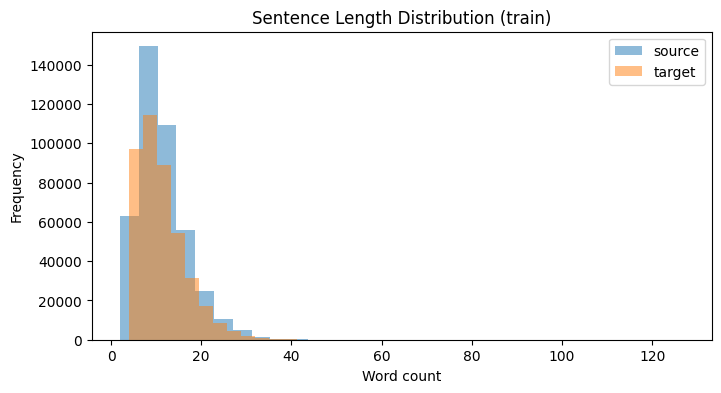

In [5]:
import matplotlib.pyplot as plt

def word_count(text):
    return len(str(text).split())

for split, df in dfs.items():
    df['source_len'] = df['source'].apply(word_count)
    df['target_len'] = df['target'].apply(word_count)
    print(f"\n{split} — source length: mean={df['source_len'].mean():.1f}, "
          f"median={df['source_len'].median()}, max={df['source_len'].max()}")
    print(f"{split} — target length: mean={df['target_len'].mean():.1f}, "
          f"median={df['target_len'].median()}, max={df['target_len'].max()}")

# Plot for train split
plt.figure(figsize=(8,4))
plt.hist(dfs['train']['source_len'], bins=30, alpha=0.5, label='source')
plt.hist(dfs['train']['target_len'], bins=30, alpha=0.5, label='target')
plt.xlabel('Word count')
plt.ylabel('Frequency')
plt.title('Sentence Length Distribution (train)')
plt.legend()
plt.show()

# Random sample for manual eyeballing

In [6]:
sample = dfs['train'].sample(15, random_state=42)
for i, row in sample.iterrows():
    print(f"SOURCE: {row['source']}")
    print(f"TARGET: {row['target']}")
    print('-' * 60)

SOURCE: তার গল্পের স্বামীরা যে অবসাদে থাকেন তার অন্যতম কারণ তো স্ত্রীকে সুখে না রাখতে পারা।
TARGET: তার গল্পে স্বামীদের অবসাদের অন্যতম কারণ হলো স্ত্রীকে সুখী রাখা নয়।
------------------------------------------------------------
SOURCE: তারপর, রক্তনালী ধরে লোহিত কণিকা অক্সিজেন নিয়ে ছোটে কোষের কাছে।
TARGET: এরপর, রক্তনালির মাধ্যমে লোহিতকণিকাগুলো কোষগুলোতে অক্সিজেন নিয়ে আসে।
------------------------------------------------------------
SOURCE: আর খানাতের শাসককে বলা হত 'খান'।
TARGET: আর খানাতের শাসককে খান বলে অভিহিত করা হতো।
------------------------------------------------------------
SOURCE: তবে লরেন কিন্তু অন্যান্য অসাধারণ প্রতিভাধর ব্যক্তিদের মতো নয়।
TARGET: কিন্তু, লোরেন অন্যান্য অসাধারণ মেধার মতো নন।
------------------------------------------------------------
SOURCE: পালিয়ে আসা রোহিঙ্গা হিন্দু শরণার্থীরা কী বলছেন?
TARGET: রোহিঙ্গা হিন্দু উদ্বাস্তুরা কি বলছে?
------------------------------------------------------------
SOURCE: দেখিয়েছেন পশ্চিমা অভিজ্ঞতাবাদের সাথে ইসলামের বিরোধ নে